In [4]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

cases_path = ROOT / "data/synthetic/disease_cases.csv"
thresholds_path = ROOT / "data/processed/recovery_thresholds.csv"

print("Cases file exists:", cases_path.exists())
print("Threshold file exists:", thresholds_path.exists())

scenario_recovery = pd.read_csv(
    cases_path,
    parse_dates=["year_month"]
)

thresholds = pd.read_csv(thresholds_path)

scenario_recovery["calendar_month"] = (
    scenario_recovery["year_month"].dt.month
)

scenario_recovery = scenario_recovery.merge(
    thresholds[
        ["district_id", "disease_id", "calendar_month", "threshold_cases"]
    ],
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="many_to_one"
)

print("\nScenario recovery rows:", len(scenario_recovery))
print("Scenarios:", scenario_recovery["scenario_id"].unique())
print("Missing thresholds:", scenario_recovery["threshold_cases"].isna().sum())

display(scenario_recovery.head())

Cases file exists: True
Threshold file exists: True

Scenario recovery rows: 8400
Scenarios: ['baseline' 'delayed_monsoon' 'heavy_rain_decline' 'prolonged_wet'
 'warmer' 'warm_wet' 'irregular_rain']
Missing thresholds: 0


,year_month,district_id,disease_id,scenario_id,cases,cases_per_100k,data_type,calendar_month,threshold_cases
0,2015-01-01,chn,dengue,baseline,275,3.929,synthetic_observed,1,277.2
1,2015-02-01,chn,dengue,baseline,179,2.557,synthetic_observed,2,235.2
2,2015-03-01,chn,dengue,baseline,175,2.500,synthetic_observed,3,210.0
3,2015-04-01,chn,dengue,baseline,53,0.757,synthetic_observed,4,135.6
4,2015-05-01,chn,dengue,baseline,50,0.714,synthetic_observed,5,108.0


In [3]:
from pathlib import Path
import pandas as pd

# Locate project root
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load synthetic disease trajectories
data_path = ROOT / "data/synthetic/disease_cases.csv"

scenario_recovery = pd.read_csv(
    data_path,
    parse_dates=["year_month"]
)

# Load seasonal recovery thresholds
thresholds = pd.read_csv(
    ROOT / "data/processed/recovery_thresholds.csv"
)

# Match thresholds using district, disease and calendar month
scenario_recovery["calendar_month"] = (
    scenario_recovery["year_month"].dt.month
)

scenario_recovery = scenario_recovery.merge(
    thresholds[
        ["district_id", "disease_id", "calendar_month", "threshold_cases"]
    ],
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="many_to_one"
)

# Standardize the threshold column name
scenario_recovery = scenario_recovery.rename(
    columns={"threshold_cases": "threshold_cases"}
)

print("Scenario recovery rows:", len(scenario_recovery))
print("Scenarios:", scenario_recovery["scenario_id"].unique())
print("Missing thresholds:", scenario_recovery["threshold_cases"].isna().sum())

display(scenario_recovery.head())

Scenario recovery rows: 8400
Scenarios: ['baseline' 'delayed_monsoon' 'heavy_rain_decline' 'prolonged_wet'
 'warmer' 'warm_wet' 'irregular_rain']
Missing thresholds: 0


,year_month,district_id,disease_id,scenario_id,cases,cases_per_100k,data_type,calendar_month,threshold_cases
0,2015-01-01,chn,dengue,baseline,275,3.929,synthetic_observed,1,277.2
1,2015-02-01,chn,dengue,baseline,179,2.557,synthetic_observed,2,235.2
2,2015-03-01,chn,dengue,baseline,175,2.500,synthetic_observed,3,210.0
3,2015-04-01,chn,dengue,baseline,53,0.757,synthetic_observed,4,135.6
4,2015-05-01,chn,dengue,baseline,50,0.714,synthetic_observed,5,108.0


In [8]:
# ============================================================
# STEP 2: VERIFY BASELINE AND CLIMATE SCENARIO ALIGNMENT
# EpiMetrics-Climate | Notebook 07
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Define unique observation identifiers
# ------------------------------------------------------------

KEYS = [
    "district_id",
    "disease_id",
    "year_month"
]

# ------------------------------------------------------------
# 2. Verify required columns exist
# ------------------------------------------------------------

required_columns = KEYS + [
    "scenario_id",
    "cases",
    "threshold_cases"
]

missing_columns = [
    col for col in required_columns
    if col not in scenario_recovery.columns
]

assert len(missing_columns) == 0, (
    f"Missing required columns: {missing_columns}"
)

print("PASS: All required columns exist.")

# ------------------------------------------------------------
# 3. Check for duplicate observations
# ------------------------------------------------------------

duplicate_count = scenario_recovery.duplicated(
    subset=KEYS + ["scenario_id"]
).sum()

print("Duplicate observations:", duplicate_count)

assert duplicate_count == 0, (
    "Duplicate district-disease-month-scenario records detected!"
)

print("PASS: No duplicate observations.")

# ------------------------------------------------------------
# 4. Check missing values
# ------------------------------------------------------------

missing_cases = scenario_recovery["cases"].isna().sum()

missing_thresholds = (
    scenario_recovery["threshold_cases"].isna().sum()
)

print("Missing case values:", missing_cases)
print("Missing threshold values:", missing_thresholds)

assert missing_cases == 0, "Missing case values detected!"

assert missing_thresholds == 0, (
    "Missing recovery threshold values detected!"
)

print("PASS: No missing case or threshold values.")

# ------------------------------------------------------------
# 5. Extract baseline observations
# ------------------------------------------------------------

baseline_keys = (
    scenario_recovery
    .loc[
        scenario_recovery["scenario_id"] == "baseline",
        KEYS
    ]
    .drop_duplicates()
    .copy()
)

assert len(baseline_keys) > 0, (
    "Baseline scenario contains no observations!"
)

print("Baseline observations:", len(baseline_keys))

# ------------------------------------------------------------
# 6. Identify climate scenarios
# ------------------------------------------------------------

climate_scenarios = [
    scenario
    for scenario in scenario_recovery["scenario_id"].unique()
    if scenario != "baseline"
]

climate_scenarios = sorted(climate_scenarios)

print("Climate scenarios:", climate_scenarios)

# ------------------------------------------------------------
# 7. Compare each scenario against the baseline
# ------------------------------------------------------------

alignment_results = []

for scenario in climate_scenarios:

    scenario_keys = (
        scenario_recovery
        .loc[
            scenario_recovery["scenario_id"] == scenario,
            KEYS
        ]
        .drop_duplicates()
        .copy()
    )

    comparison = baseline_keys.merge(
        scenario_keys,
        on=KEYS,
        how="outer",
        indicator=True,
        validate="one_to_one"
    )

    baseline_only_count = int(
        (comparison["_merge"] == "left_only").sum()
    )

    scenario_only_count = int(
        (comparison["_merge"] == "right_only").sum()
    )

    alignment_results.append({
        "scenario": scenario,
        "baseline_observations": len(baseline_keys),
        "scenario_observations": len(scenario_keys),
        "baseline_only": baseline_only_count,
        "scenario_only": scenario_only_count
    })

# ------------------------------------------------------------
# 8. Create alignment summary
# ------------------------------------------------------------

alignment_summary = pd.DataFrame(alignment_results)

print("\n=== SCENARIO ALIGNMENT CHECK ===")

display(alignment_summary)

# ------------------------------------------------------------
# 9. Final validation
# ------------------------------------------------------------

assert not alignment_summary.empty, (
    "No climate scenarios were found!"
)

assert (
    alignment_summary["baseline_only"] == 0
).all(), (
    "Some baseline observations are missing from climate scenarios!"
)

assert (
    alignment_summary["scenario_only"] == 0
).all(), (
    "Some climate scenarios contain unmatched observations!"
)


print("Total dataset rows:", len(scenario_recovery))
print("Baseline observations:", len(baseline_keys))
print("Climate scenarios checked:", len(climate_scenarios))

PASS: All required columns exist.
Duplicate observations: 0
PASS: No duplicate observations.
Missing case values: 0
Missing threshold values: 0
PASS: No missing case or threshold values.
Baseline observations: 1200
Climate scenarios: ['delayed_monsoon', 'heavy_rain_decline', 'irregular_rain', 'prolonged_wet', 'warm_wet', 'warmer']

=== SCENARIO ALIGNMENT CHECK ===


,scenario,baseline_observations,scenario_observations,baseline_only,scenario_only
0,delayed_monsoon,1200,1200,0,0
1,heavy_rain_decline,1200,1200,0,0
2,irregular_rain,1200,1200,0,0
3,prolonged_wet,1200,1200,0,0
4,warm_wet,1200,1200,0,0
5,warmer,1200,1200,0,0


Total dataset rows: 8400
Baseline observations: 1200
Climate scenarios checked: 6


In [9]:

#  PREPARE OUTBREAK AND RECOVERY INDICATORS


import numpy as np
import pandas as pd

# Create a separate working copy
recovery_analysis = scenario_recovery.copy()

# Ensure dates are correctly formatted
recovery_analysis["year_month"] = pd.to_datetime(
    recovery_analysis["year_month"]
)

# Sort chronologically within each scenario
recovery_analysis = recovery_analysis.sort_values(
    [
        "district_id",
        "disease_id",
        "scenario_id",
        "year_month"
    ]
).reset_index(drop=True)

# Validate case and threshold values
assert (
    recovery_analysis["cases"] >= 0
).all(), "Negative case counts detected!"

assert (
    recovery_analysis["threshold_cases"] > 0
).all(), "Recovery thresholds must be positive!"

# Identify months above the seasonal outbreak threshold
recovery_analysis["above_threshold"] = (
    recovery_analysis["cases"]
    > recovery_analysis["threshold_cases"]
)

# Identify months at or below the threshold
recovery_analysis["below_threshold"] = (
    recovery_analysis["cases"]
    <= recovery_analysis["threshold_cases"]
)

# Calculate how far cases exceed the threshold
recovery_analysis["threshold_excess"] = np.maximum(
    recovery_analysis["cases"]
    - recovery_analysis["threshold_cases"],
    0
)

# Summarize outbreak-month frequency by scenario and disease
outbreak_summary = (
    recovery_analysis
    .groupby(
        ["scenario_id", "disease_id"],
        as_index=False
    )
    .agg(
        total_months=("year_month", "count"),
        outbreak_months=("above_threshold", "sum"),
        mean_threshold_excess=("threshold_excess", "mean")
    )
)

outbreak_summary["outbreak_month_pct"] = (
    100
    * outbreak_summary["outbreak_months"]
    / outbreak_summary["total_months"]
)

print("=== OUTBREAK INDICATOR VALIDATION ===")
print("Total observations:", len(recovery_analysis))
print(
    "Above-threshold months:",
    int(recovery_analysis["above_threshold"].sum())
)
print(
    "Below-threshold months:",
    int(recovery_analysis["below_threshold"].sum())
)

assert (
    recovery_analysis["above_threshold"]
    != recovery_analysis["below_threshold"]
).all(), "Threshold classification failed!"

print("\n=== OUTBREAK MONTHS BY SCENARIO AND DISEASE ===")
display(outbreak_summary.round(3))

print("\nPASS: Outbreak and recovery indicators prepared.")

=== OUTBREAK INDICATOR VALIDATION ===
Total observations: 8400
Above-threshold months: 1975
Below-threshold months: 6425

=== OUTBREAK MONTHS BY SCENARIO AND DISEASE ===


,scenario_id,disease_id,total_months,outbreak_months,mean_threshold_excess,outbreak_month_pct
0,baseline,dengue,600,130,11.282,21.667
1,baseline,malaria,600,129,3.500,21.500
2,delayed_monsoon,dengue,600,143,12.539,23.833
3,delayed_monsoon,malaria,600,143,3.898,23.833
4,heavy_rain_decline,dengue,600,142,12.127,23.667
5,heavy_rain_decline,malaria,600,136,3.737,22.667
6,irregular_rain,dengue,600,189,16.748,31.500
7,irregular_rain,malaria,600,187,5.560,31.167
8,prolonged_wet,dengue,600,150,14.887,25.000
9,prolonged_wet,malaria,600,151,4.481,25.167



PASS: Outbreak and recovery indicators prepared.


In [10]:

#  DETECT OUTBREAKS AND SUSTAINED RECOVERY


import numpy as np
import pandas as pd

SUSTAINED_MONTHS = 3

GROUP_COLS = ["district_id", "disease_id", "scenario_id"]

def analyse_recovery(group, sustained_months=3):
    """
    Detect outbreak episodes and sustained recovery.

    Recovery is confirmed when cases remain at or below the
    seasonal threshold for the specified consecutive months.

    Recovery time is measured from outbreak onset to the
    final month of the qualifying recovery window.

    A renewed above-threshold month before recovery
    confirmation is counted as a recovery interruption.
    """

    group = group.sort_values("year_month").reset_index(drop=True)

    dates = pd.to_datetime(group["year_month"])
    above = group["above_threshold"].astype(bool).to_numpy()

    results = []
    i = 0
    episode_number = 0

    while i < len(group):

        # Find the next above-threshold month
        if not above[i]:
            i += 1
            continue

        episode_number += 1
        onset_idx = i
        interruptions = 0
        below_streak = 0
        recovered_idx = None

        j = i + 1

        while j < len(group):

            if above[j]:
                if below_streak > 0:
                    interruptions += 1

                below_streak = 0

            else:
                below_streak += 1

                if below_streak >= sustained_months:
                    recovered_idx = j
                    break

            j += 1

        onset_date = dates.iloc[onset_idx]

        if recovered_idx is not None:
            recovery_date = dates.iloc[recovered_idx]

            recovery_months = (
                (recovery_date.year - onset_date.year) * 12
                + recovery_date.month - onset_date.month
            )

            status = "recovered"
            next_index = recovered_idx + 1

        else:
            recovery_date = pd.NaT
            recovery_months = np.nan
            status = "unresolved"
            next_index = len(group)

        results.append({
            "district_id": group["district_id"].iloc[0],
            "disease_id": group["disease_id"].iloc[0],
            "scenario_id": group["scenario_id"].iloc[0],
            "episode_number": episode_number,
            "outbreak_onset": onset_date,
            "recovery_date": recovery_date,
            "recovery_months": recovery_months,
            "recovery_interruptions": interruptions,
            "recovery_status": status
        })

        i = next_index

    return results


# Run recovery detection for every district/disease/scenario
recovery_results = []

for _, group in recovery_analysis.groupby(GROUP_COLS):
    recovery_results.extend(
        analyse_recovery(
            group,
            sustained_months=SUSTAINED_MONTHS
        )
    )

recovery_results = pd.DataFrame(recovery_results)

print("=== SUSTAINED RECOVERY ANALYSIS ===")
print("Outbreak episodes detected:", len(recovery_results))

if not recovery_results.empty:

    print(
        "Recovered episodes:",
        int((recovery_results["recovery_status"] == "recovered").sum())
    )

    print(
        "Unresolved episodes:",
        int((recovery_results["recovery_status"] == "unresolved").sum())
    )

    print(
        "Total recovery interruptions:",
        int(recovery_results["recovery_interruptions"].sum())
    )

    display(recovery_results.head(15))

else:
    print("No above-threshold outbreak episodes detected.")

print("\nPASS: Recovery episode analysis completed.")

=== SUSTAINED RECOVERY ANALYSIS ===
Outbreak episodes detected: 602
Recovered episodes: 578
Unresolved episodes: 24
Total recovery interruptions: 429


,district_id,disease_id,scenario_id,episode_number,outbreak_onset,recovery_date,recovery_months,recovery_interruptions,recovery_status
0,cbe,dengue,baseline,1,2015-04-01,2016-02-01,10.0,2,recovered
1,cbe,dengue,baseline,2,2018-07-01,2019-04-01,9.0,2,recovered
2,cbe,dengue,baseline,3,2019-12-01,2020-06-01,6.0,0,recovered
3,cbe,dengue,baseline,4,2020-09-01,2020-12-01,3.0,0,recovered
4,cbe,dengue,baseline,5,2021-07-01,2021-11-01,4.0,0,recovered
5,cbe,dengue,baseline,6,2022-10-01,2023-04-01,6.0,0,recovered
6,cbe,dengue,baseline,7,2023-07-01,2023-10-01,3.0,0,recovered
7,cbe,dengue,baseline,8,2023-11-01,2024-02-01,3.0,0,recovered
8,cbe,dengue,delayed_monsoon,1,2015-04-01,2016-02-01,10.0,2,recovered
9,cbe,dengue,delayed_monsoon,2,2018-07-01,2019-04-01,9.0,2,recovered



PASS: Recovery episode analysis completed.


In [11]:

#  BASELINE VS CLIMATE SCENARIO RECOVERY COMPARISON


import numpy as np
import pandas as pd

assert "recovery_results" in globals(), (
    "Run Step 4 before this cell."
)

assert not recovery_results.empty, (
    "No outbreak episodes available for comparison."
)

# 1. Summarize recovery outcomes for each scenario
scenario_summary = (
    recovery_results
    .groupby(
        ["district_id", "disease_id", "scenario_id"],
        as_index=False
    )
    .agg(
        outbreak_episodes=("episode_number", "count"),
        recovered_episodes=(
            "recovery_status",
            lambda x: (x == "recovered").sum()
        ),
        unresolved_episodes=(
            "recovery_status",
            lambda x: (x == "unresolved").sum()
        ),
        mean_recovery_months=("recovery_months", "mean"),
        median_recovery_months=("recovery_months", "median"),
        total_interruptions=("recovery_interruptions", "sum")
    )
)

# 2. Extract baseline outcomes
baseline_summary = (
    scenario_summary[
        scenario_summary["scenario_id"] == "baseline"
    ]
    .drop(columns=["scenario_id"])
    .rename(
        columns={
            "outbreak_episodes": "baseline_episodes",
            "recovered_episodes": "baseline_recovered",
            "unresolved_episodes": "baseline_unresolved",
            "mean_recovery_months": "baseline_mean_recovery",
            "median_recovery_months": "baseline_median_recovery",
            "total_interruptions": "baseline_interruptions"
        }
    )
)

# 3. Compare climate scenarios with baseline
climate_comparison = scenario_summary[
    scenario_summary["scenario_id"] != "baseline"
].merge(
    baseline_summary,
    on=["district_id", "disease_id"],
    how="left",
    validate="many_to_one"
)

assert climate_comparison["baseline_episodes"].notna().all(), (
    "Some climate scenario groups have no baseline comparison."
)

# 4. Calculate differences
climate_comparison["mean_recovery_difference_months"] = (
    climate_comparison["mean_recovery_months"]
    - climate_comparison["baseline_mean_recovery"]
)

climate_comparison["interruption_difference"] = (
    climate_comparison["total_interruptions"]
    - climate_comparison["baseline_interruptions"]
)

climate_comparison["unresolved_difference"] = (
    climate_comparison["unresolved_episodes"]
    - climate_comparison["baseline_unresolved"]
)

climate_comparison["episode_count_difference"] = (
    climate_comparison["outbreak_episodes"]
    - climate_comparison["baseline_episodes"]
)

# 5. Display results
print("=== RECOVERY SUMMARY BY SCENARIO ===")
display(scenario_summary.round(2))

print("\n=== BASELINE VS CLIMATE RECOVERY COMPARISON ===")

display(
    climate_comparison[
        [
            "district_id",
            "disease_id",
            "scenario_id",
            "outbreak_episodes",
            "baseline_episodes",
            "mean_recovery_months",
            "baseline_mean_recovery",
            "mean_recovery_difference_months",
            "total_interruptions",
            "interruption_difference",
            "unresolved_episodes",
            "unresolved_difference"
        ]
    ].round(2)
)

print("\nPASS: Climate recovery comparison completed.")

=== RECOVERY SUMMARY BY SCENARIO ===


,district_id,disease_id,scenario_id,outbreak_episodes,recovered_episodes,unresolved_episodes,mean_recovery_months,median_recovery_months,total_interruptions
0,cbe,dengue,baseline,8,8,0,5.50,5.0,4
1,cbe,dengue,delayed_monsoon,6,6,0,8.00,7.5,5
2,cbe,dengue,heavy_rain_decline,6,6,0,8.00,7.5,7
3,cbe,dengue,irregular_rain,7,6,1,8.00,7.5,7
4,cbe,dengue,prolonged_wet,6,6,0,8.00,7.5,5
...,...,...,...,...,...,...,...,...,...
65,try,malaria,heavy_rain_decline,8,7,1,8.14,8.0,11
66,try,malaria,irregular_rain,7,6,1,8.33,7.5,14
67,try,malaria,prolonged_wet,8,7,1,8.29,8.0,11
68,try,malaria,warm_wet,7,7,0,7.00,4.0,9



=== BASELINE VS CLIMATE RECOVERY COMPARISON ===


,district_id,disease_id,scenario_id,outbreak_episodes,baseline_episodes,mean_recovery_months,baseline_mean_recovery,mean_recovery_difference_months,total_interruptions,interruption_difference,unresolved_episodes,unresolved_difference
0,cbe,dengue,delayed_monsoon,6,8,8.00,5.50,2.50,5,1,0,0
1,cbe,dengue,heavy_rain_decline,6,8,8.00,5.50,2.50,7,3,0,0
2,cbe,dengue,irregular_rain,7,8,8.00,5.50,2.50,7,3,1,1
3,cbe,dengue,prolonged_wet,6,8,8.00,5.50,2.50,5,1,0,0
4,cbe,dengue,warm_wet,7,8,6.86,5.50,1.36,5,1,0,0
5,cbe,dengue,warmer,7,8,6.57,5.50,1.07,4,0,0,0
6,cbe,malaria,delayed_monsoon,10,11,5.70,4.91,0.79,7,2,0,0
7,cbe,malaria,heavy_rain_decline,10,11,5.70,4.91,0.79,7,2,0,0
8,cbe,malaria,irregular_rain,10,11,7.11,4.91,2.20,6,1,1,1
9,cbe,malaria,prolonged_wet,9,11,6.44,4.91,1.54,7,2,0,0



PASS: Climate recovery comparison completed.


In [12]:
print(recovery_results["district_id"].unique())
print(recovery_results["disease_id"].unique())


['cbe' 'chn' 'mdu' 'tnj' 'try']
['dengue' 'malaria']


In [13]:

# Inspect outbreak timing across climate scenarios

assert not recovery_results.empty, "No recovery episodes available."

episode_timing = recovery_results[
    [
        "district_id",
        "disease_id",
        "scenario_id",
        "episode_number",
        "outbreak_onset",
        "recovery_date",
        "recovery_months",
        "recovery_interruptions",
        "recovery_status"
    ]
].copy()

episode_timing["outbreak_onset"] = pd.to_datetime(
    episode_timing["outbreak_onset"]
)

# Focus on Chennai dengue for the first comparison
chennai_dengue = episode_timing[
    (episode_timing["district_id"] == "chn") &
    (episode_timing["disease_id"] == "dengue")
].sort_values(
    ["scenario_id", "outbreak_onset"]
)

print("=== CHENNAI DENGUE OUTBREAK EPISODES ===")

display(chennai_dengue)

print("\n=== EPISODE COUNTS BY SCENARIO ===")

display(
    chennai_dengue.groupby("scenario_id")
    .agg(
        episodes=("episode_number", "count"),
        first_onset=("outbreak_onset", "min"),
        last_onset=("outbreak_onset", "max"),
        unresolved=(
            "recovery_status",
            lambda x: (x == "unresolved").sum()
        )
    )
    .reset_index()
)


=== CHENNAI DENGUE OUTBREAK EPISODES ===


,district_id,disease_id,scenario_id,episode_number,outbreak_onset,recovery_date,recovery_months,recovery_interruptions,recovery_status
118,chn,dengue,baseline,1,2015-09-01,2015-12-01,3.0,0,recovered
119,chn,dengue,baseline,2,2017-02-01,2017-05-01,3.0,0,recovered
120,chn,dengue,baseline,3,2018-10-01,2019-01-01,3.0,0,recovered
121,chn,dengue,baseline,4,2019-09-01,2020-01-01,4.0,0,recovered
122,chn,dengue,baseline,5,2022-10-01,2023-08-01,10.0,2,recovered
123,chn,dengue,baseline,6,2023-10-01,2024-01-01,3.0,0,recovered
124,chn,dengue,baseline,7,2024-10-01,NaT,NaN,0,unresolved
125,chn,dengue,delayed_monsoon,1,2015-09-01,2015-12-01,3.0,0,recovered
126,chn,dengue,delayed_monsoon,2,2017-02-01,2017-05-01,3.0,0,recovered
127,chn,dengue,delayed_monsoon,3,2018-10-01,2019-01-01,3.0,0,recovered



=== EPISODE COUNTS BY SCENARIO ===


,scenario_id,episodes,first_onset,last_onset,unresolved
0,baseline,7,2015-09-01,2024-10-01,1
1,delayed_monsoon,6,2015-09-01,2024-10-01,1
2,heavy_rain_decline,7,2015-09-01,2024-10-01,1
3,irregular_rain,6,2015-09-01,2024-03-01,1
4,prolonged_wet,6,2015-09-01,2024-10-01,1
5,warm_wet,5,2015-09-01,2022-10-01,0
6,warmer,5,2015-09-01,2022-10-01,0


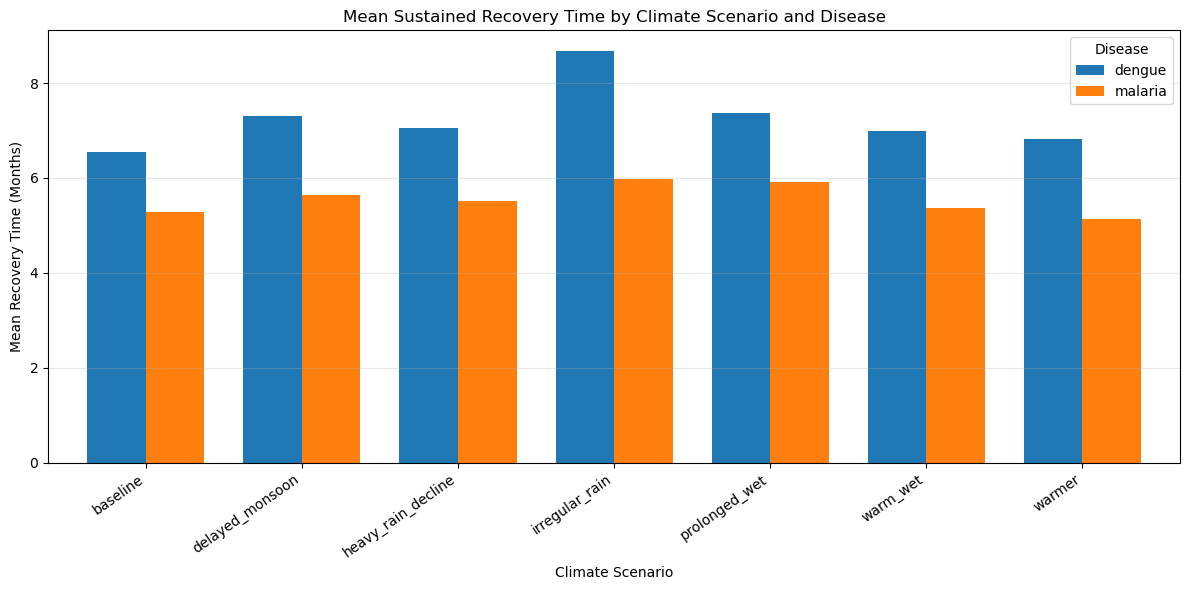

=== MEAN RECOVERY TIME BY SCENARIO ===


,scenario_id,disease_id,mean_recovery_months,recovered_episodes
0,baseline,dengue,6.55,38
1,baseline,malaria,5.28,50
2,delayed_monsoon,dengue,7.31,35
3,delayed_monsoon,malaria,5.64,50
4,heavy_rain_decline,dengue,7.06,36
5,heavy_rain_decline,malaria,5.52,50
6,irregular_rain,dengue,8.68,31
7,irregular_rain,malaria,5.98,43
8,prolonged_wet,dengue,7.37,35
9,prolonged_wet,malaria,5.92,49



PASS: Recovery visualization completed.


In [14]:

#  VISUALIZE CLIMATE SCENARIO RECOVERY OUTCOMES


import matplotlib.pyplot as plt
import pandas as pd

# Average recovery time by scenario and disease
plot_data = (
    recovery_results[
        recovery_results["recovery_status"] == "recovered"
    ]
    .groupby(["scenario_id", "disease_id"], as_index=False)
    .agg(
        mean_recovery_months=("recovery_months", "mean"),
        recovered_episodes=("episode_number", "count")
    )
)

scenario_order = [
    "baseline",
    "delayed_monsoon",
    "heavy_rain_decline",
    "irregular_rain",
    "prolonged_wet",
    "warm_wet",
    "warmer"
]

plot_table = plot_data.pivot(
    index="scenario_id",
    columns="disease_id",
    values="mean_recovery_months"
)

plot_table = plot_table.reindex(scenario_order)

# Plot average recovery duration
ax = plot_table.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "Mean Sustained Recovery Time by Climate Scenario and Disease"
)
ax.set_xlabel("Climate Scenario")
ax.set_ylabel("Mean Recovery Time (Months)")
ax.legend(title="Disease")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Display numerical summary
print("=== MEAN RECOVERY TIME BY SCENARIO ===")
display(plot_data.round(2))

print("\nPASS: Recovery visualization completed.")

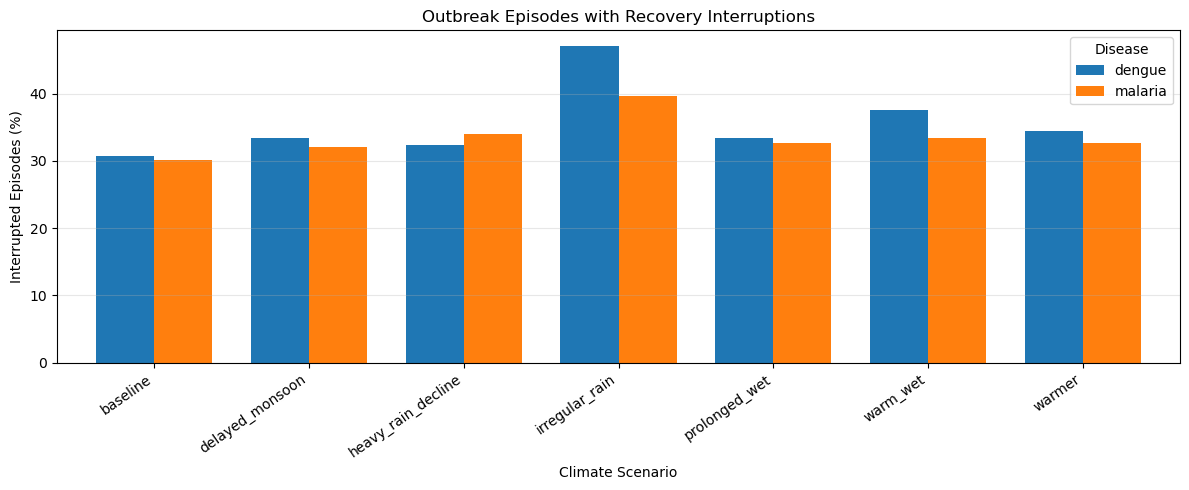

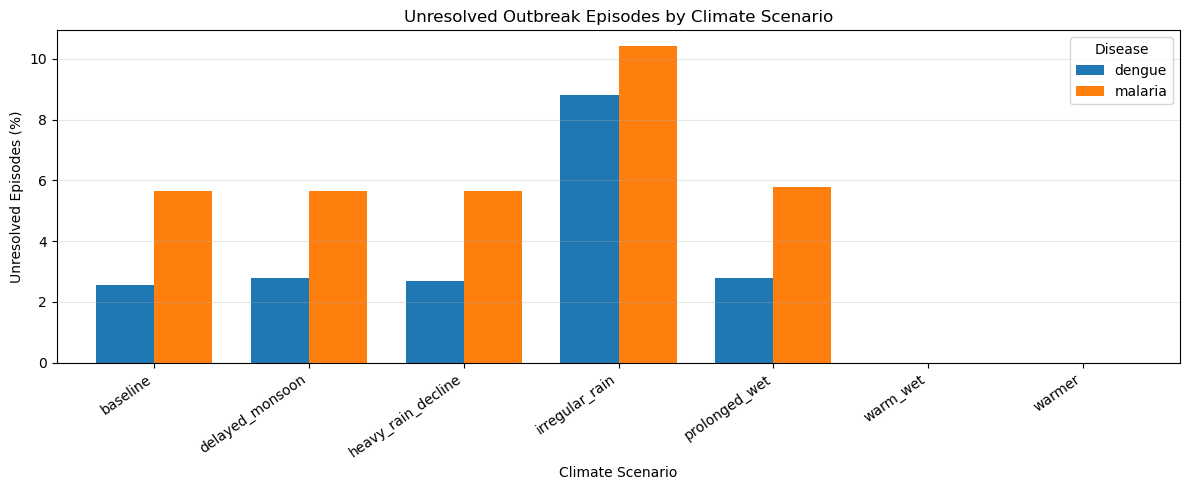

=== RECOVERY INTERRUPTION AND UNRESOLVED SUMMARY ===


,scenario_id,disease_id,total_episodes,total_interruptions,interrupted_episodes,unresolved_episodes,interrupted_pct,unresolved_pct
0,baseline,dengue,39,30,12,1,30.77,2.56
1,baseline,malaria,53,29,16,3,30.19,5.66
2,delayed_monsoon,dengue,36,28,12,1,33.33,2.78
3,delayed_monsoon,malaria,53,31,17,3,32.08,5.66
4,heavy_rain_decline,dengue,37,29,12,1,32.43,2.70
5,heavy_rain_decline,malaria,53,32,18,3,33.96,5.66
6,irregular_rain,dengue,34,35,16,3,47.06,8.82
7,irregular_rain,malaria,48,44,19,5,39.58,10.42
8,prolonged_wet,dengue,36,27,12,1,33.33,2.78
9,prolonged_wet,malaria,52,33,17,3,32.69,5.77



PASS: Interruption and unresolved-outbreak analysis completed.


In [15]:

# RECOVERY INTERRUPTIONS AND UNRESOLVED OUTBREAKS


import pandas as pd
import matplotlib.pyplot as plt

assert not recovery_results.empty, "No recovery episodes available."

# Summarize outcomes by scenario and disease
interruption_summary = (
    recovery_results
    .groupby(["scenario_id", "disease_id"], as_index=False)
    .agg(
        total_episodes=("episode_number", "count"),
        total_interruptions=("recovery_interruptions", "sum"),
        interrupted_episodes=(
            "recovery_interruptions",
            lambda x: (x > 0).sum()
        ),
        unresolved_episodes=(
            "recovery_status",
            lambda x: (x == "unresolved").sum()
        )
    )
)

# Calculate comparable percentages
interruption_summary["interrupted_pct"] = (
    100
    * interruption_summary["interrupted_episodes"]
    / interruption_summary["total_episodes"]
)

interruption_summary["unresolved_pct"] = (
    100
    * interruption_summary["unresolved_episodes"]
    / interruption_summary["total_episodes"]
)

scenario_order = [
    "baseline",
    "delayed_monsoon",
    "heavy_rain_decline",
    "irregular_rain",
    "prolonged_wet",
    "warm_wet",
    "warmer"
]

# Plot 1: Percentage of episodes with recovery interruptions
interrupted_plot = interruption_summary.pivot(
    index="scenario_id",
    columns="disease_id",
    values="interrupted_pct"
).reindex(scenario_order)

ax = interrupted_plot.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75
)

ax.set_title("Outbreak Episodes with Recovery Interruptions")
ax.set_xlabel("Climate Scenario")
ax.set_ylabel("Interrupted Episodes (%)")
ax.legend(title="Disease")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Plot 2: Percentage of unresolved episodes
unresolved_plot = interruption_summary.pivot(
    index="scenario_id",
    columns="disease_id",
    values="unresolved_pct"
).reindex(scenario_order)

ax = unresolved_plot.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75
)

ax.set_title("Unresolved Outbreak Episodes by Climate Scenario")
ax.set_xlabel("Climate Scenario")
ax.set_ylabel("Unresolved Episodes (%)")
ax.legend(title="Disease")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("=== RECOVERY INTERRUPTION AND UNRESOLVED SUMMARY ===")
display(interruption_summary.round(2))

print("\nPASS: Interruption and unresolved-outbreak analysis completed.")

In [16]:


#  BASELINE VS CLIMATE RECOVERY DELAY (DELTA TSR)


import numpy as np
import pandas as pd

assert not recovery_results.empty, "Run Step 4 first."

episodes = recovery_results.copy()
episodes["outbreak_onset"] = pd.to_datetime(
    episodes["outbreak_onset"]
)

# Exclude outbreaks already active in the first observed month
# of each district/disease series (potential left censoring).
series_start = (
    recovery_analysis
    .groupby(["district_id", "disease_id", "scenario_id"])["year_month"]
    .min()
    .rename("series_start")
    .reset_index()
)

episodes = episodes.merge(
    series_start,
    on=["district_id", "disease_id", "scenario_id"],
    how="left",
    validate="many_to_one"
)

episodes = episodes[
    episodes["outbreak_onset"] > episodes["series_start"]
].copy()

# Separate baseline and climate scenario episodes
baseline_episodes = (
    episodes[episodes["scenario_id"] == "baseline"]
    [
        [
            "district_id",
            "disease_id",
            "outbreak_onset",
            "recovery_months",
            "recovery_status",
            "recovery_interruptions"
        ]
    ]
    .rename(columns={
        "recovery_months": "baseline_tsr",
        "recovery_status": "baseline_status",
        "recovery_interruptions": "baseline_interruptions"
    })
)

climate_episodes = episodes[
    episodes["scenario_id"] != "baseline"
].copy()

# Match only episodes with identical onset dates
matched_recovery = climate_episodes.merge(
    baseline_episodes,
    on=["district_id", "disease_id", "outbreak_onset"],
    how="inner",
    validate="many_to_one"
)

# Delta TSR is defined only when both episodes recovered
both_recovered = (
    (matched_recovery["recovery_status"] == "recovered") &
    (matched_recovery["baseline_status"] == "recovered")
)

matched_recovery["delta_tsr_months"] = np.where(
    both_recovered,
    matched_recovery["recovery_months"]
    - matched_recovery["baseline_tsr"],
    np.nan
)

matched_recovery["delta_interruptions"] = (
    matched_recovery["recovery_interruptions"]
    - matched_recovery["baseline_interruptions"]
)

# Summary by scenario and disease
delta_tsr_summary = (
    matched_recovery
    .groupby(["scenario_id", "disease_id"], as_index=False)
    .agg(
        matched_episodes=("outbreak_onset", "count"),
        comparable_recovered=("delta_tsr_months", "count"),
        mean_delta_tsr=("delta_tsr_months", "mean"),
        median_delta_tsr=("delta_tsr_months", "median"),
        mean_delta_interruptions=("delta_interruptions", "mean")
    )
)

print("=== MATCHED RECOVERY ANALYSIS ===")
print("Matched episodes:", len(matched_recovery))
print("Episodes recovered in both scenarios:", int(both_recovered.sum()))

print("\n=== CLIMATE RECOVERY DELAY (DELTA TSR) ===")
display(delta_tsr_summary.round(2))

print("\nPASS: Matched recovery comparison completed.")


=== MATCHED RECOVERY ANALYSIS ===
Matched episodes: 497
Episodes recovered in both scenarios: 483

=== CLIMATE RECOVERY DELAY (DELTA TSR) ===


,scenario_id,disease_id,matched_episodes,comparable_recovered,mean_delta_tsr,median_delta_tsr,mean_delta_interruptions
0,delayed_monsoon,dengue,36,35,0.46,0.0,-0.06
1,delayed_monsoon,malaria,52,49,0.31,0.0,0.04
2,heavy_rain_decline,dengue,37,36,0.31,0.0,-0.03
3,heavy_rain_decline,malaria,52,49,0.22,0.0,0.06
4,irregular_rain,dengue,31,31,1.32,0.0,0.00
5,irregular_rain,malaria,45,43,0.72,0.0,0.29
6,prolonged_wet,dengue,36,35,0.51,0.0,-0.08
7,prolonged_wet,malaria,51,48,0.60,0.0,0.12
8,warm_wet,dengue,32,32,-0.22,0.0,-0.16
9,warm_wet,malaria,46,46,0.13,0.0,0.11



PASS: Matched recovery comparison completed.


In [17]:


# STEP 10: FINAL RECOVERY ANALYSIS VALIDATION


import numpy as np
import pandas as pd

print("=== FINAL RECOVERY ANALYSIS VALIDATION ===")

# 1. Validate recovery durations
recovered = recovery_results[
    recovery_results["recovery_status"] == "recovered"
]

unresolved = recovery_results[
    recovery_results["recovery_status"] == "unresolved"
]

assert recovered["recovery_months"].notna().all(), (
    "Recovered episodes have missing recovery durations."
)

assert (recovered["recovery_months"] >= 3).all(), (
    "Some recovery durations are shorter than expected."
)

assert unresolved["recovery_months"].isna().all(), (
    "Unresolved episodes must not have recovery durations."
)

print("PASS: Recovery durations and unresolved statuses are valid.")

# 2. Validate interruption counts
assert (recovery_results["recovery_interruptions"] >= 0).all(), (
    "Negative interruption counts detected."
)

print("PASS: Recovery interruption counts are valid.")

# 3. Validate matched comparisons
assert (
    matched_recovery[
        ["district_id", "disease_id", "scenario_id", "outbreak_onset"]
    ].duplicated().sum() == 0
), "Duplicate matched episodes detected."

print("PASS: Matched episode records are unique.")

# 4. Check matching coverage
total_climate_episodes = len(
    episodes[episodes["scenario_id"] != "baseline"]
)

matched_count = len(matched_recovery)

matching_pct = (
    100 * matched_count / total_climate_episodes
    if total_climate_episodes > 0
    else np.nan
)

print("\n=== MATCHING COVERAGE ===")
print("Climate episodes:", total_climate_episodes)
print("Exactly matched episodes:", matched_count)
print(f"Matching coverage: {matching_pct:.2f}%")

# 5. Check valid Delta TSR comparisons
valid_delta = matched_recovery["delta_tsr_months"].notna().sum()

print("\n=== DELTA TSR VALIDATION ===")
print("Valid Delta TSR comparisons:", valid_delta)
print("Unresolved or non-comparable pairs:", matched_count - valid_delta)

if valid_delta > 0:
    print(
        "Mean Delta TSR:",
        round(matched_recovery["delta_tsr_months"].mean(), 2),
        "months"
    )
else:
    print("No valid Delta TSR comparisons available.")

# 6. Final summary
print("\n=== FINAL ANALYSIS SUMMARY ===")
print("Total outbreak episodes:", len(recovery_results))
print("Recovered episodes:", len(recovered))
print("Unresolved episodes:", len(unresolved))
print(
    "Total recovery interruptions:",
    int(recovery_results["recovery_interruptions"].sum())
)

print("\nPASS: Final recovery analysis validation completed.")


=== FINAL RECOVERY ANALYSIS VALIDATION ===
PASS: Recovery durations and unresolved statuses are valid.
PASS: Recovery interruption counts are valid.
PASS: Matched episode records are unique.

=== MATCHING COVERAGE ===
Climate episodes: 510
Exactly matched episodes: 497
Matching coverage: 97.45%

=== DELTA TSR VALIDATION ===
Valid Delta TSR comparisons: 483
Unresolved or non-comparable pairs: 14
Mean Delta TSR: 0.32 months

=== FINAL ANALYSIS SUMMARY ===
Total outbreak episodes: 602
Recovered episodes: 578
Unresolved episodes: 24
Total recovery interruptions: 429

PASS: Final recovery analysis validation completed.


In [18]:

# EXPORT FINAL RECOVERY ANALYSIS RESULTS
# EpiMetrics-Climate | Notebook 07

from pathlib import Path
import pandas as pd

# Locate the project root, whether the notebook runs
# from the project folder or its notebooks/ subfolder.
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

assert (project_root / "data").exists(), (
    "Project data folder not found. Check the notebook working directory."
)

# Create output directory
output_dir = project_root / "data" / "derived" / "recovery_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

# Export episode-level recovery results
recovery_results.to_csv(
    output_dir / "recovery_episode_results.csv",
    index=False
)

# Export scenario summaries
scenario_summary.to_csv(
    output_dir / "scenario_recovery_summary.csv",
    index=False
)

# Export baseline versus climate comparisons
climate_comparison.to_csv(
    output_dir / "climate_recovery_comparison.csv",
    index=False
)

# Export exact-onset matched episode comparisons
matched_recovery.to_csv(
    output_dir / "matched_recovery_results.csv",
    index=False
)

# Export Delta TSR summary
delta_tsr_summary.to_csv(
    output_dir / "delta_tsr_summary.csv",
    index=False
)

# Export interruption and unresolved-outbreak summary
interruption_summary.to_csv(
    output_dir / "recovery_interruption_summary.csv",
    index=False
)

# Create a final validation summary
validation_summary = pd.DataFrame([{
    "total_outbreak_episodes": len(recovery_results),
    "recovered_episodes": int(
        (recovery_results["recovery_status"] == "recovered").sum()
    ),
    "unresolved_episodes": int(
        (recovery_results["recovery_status"] == "unresolved").sum()
    ),
    "total_recovery_interruptions": int(
        recovery_results["recovery_interruptions"].sum()
    ),
    "climate_episodes": total_climate_episodes,
    "matched_episodes": matched_count,
    "matching_coverage_pct": matching_pct,
    "valid_delta_tsr_pairs": int(valid_delta),
    "mean_delta_tsr_months": matched_recovery[
        "delta_tsr_months"
    ].mean()
}])

validation_summary.to_csv(
    output_dir / "recovery_validation_summary.csv",
    index=False
)

# Verify exports
expected_files = [
    "recovery_episode_results.csv",
    "scenario_recovery_summary.csv",
    "climate_recovery_comparison.csv",
    "matched_recovery_results.csv",
    "delta_tsr_summary.csv",
    "recovery_interruption_summary.csv",
    "recovery_validation_summary.csv"
]

print("=== FINAL RECOVERY ANALYSIS EXPORT ===")

for filename in expected_files:
    file_path = output_dir / filename
    assert file_path.exists(), f"Missing export: {filename}"
    print("SAVED:", filename)

print("\nOutput directory:", output_dir)
print("Total CSV files exported:", len(expected_files))
print("\nPASS: All final recovery analysis results exported.")


=== FINAL RECOVERY ANALYSIS EXPORT ===
SAVED: recovery_episode_results.csv
SAVED: scenario_recovery_summary.csv
SAVED: climate_recovery_comparison.csv
SAVED: matched_recovery_results.csv
SAVED: delta_tsr_summary.csv
SAVED: recovery_interruption_summary.csv
SAVED: recovery_validation_summary.csv

Output directory: /Users/Trisha/Downloads/epimetrics_ukm_final/data/derived/recovery_analysis
Total CSV files exported: 7

PASS: All final recovery analysis results exported.
